# INF-8239 · Ejercicio 07 · Evaluación de impacto y auditoría de equidad

DSS territorial **sintético**. El modelo solo ordena casos para revisión humana.

In [1]:
import os, json
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200)
print(Path.cwd())

/tmp/u04/INF8239_U04_E07_Impacto_Equidad


## 1. Datos y contrato

In [2]:
!python scripts/check_environment.py

{'python_project': 'ok', 'dataset_status': 'valid', 'rows': 640, 'columns': 9}


In [3]:
!python scripts/describe_dataset.py

shape (640, 9)
target {1: 0.552, 0: 0.448}
groups {'G1': 396, 'G2': 244}
train_end 2026-09-24 00:00:00
test_start 2026-09-25 00:00:00
excluded_from_model ['case_id', 'received_date', 'protected_group', 'target']


## 2. Auditoría global, por grupo e interseccional

In [4]:
!python scripts/lab12_audit.py --model logistic

                 count  accuracy  selection_rate  recall  precision    fpr
protected_group                                                           
G1               101.0     0.703           0.446   0.653      0.711  0.250
G2                59.0     0.746           0.678   0.791      0.850  0.375
{'training_seconds': 0.025061794999999165, 'model_kb': 3.5634765625}


In [5]:
!python scripts/lab12_audit.py --model tree

                 count  accuracy  selection_rate  recall  precision    fpr
protected_group                                                           
G1               101.0     0.683           0.446   0.633      0.689  0.269
G2                59.0     0.746           0.712   0.814      0.833  0.438
{'training_seconds': 0.024698926000013444, 'model_kb': 7.9013671875}


In [6]:
for m in ["logistic", "tree"]:
    print(m, json.loads(Path(f"reports/lab12/{m}/global_metrics.json").read_text())["differences"])
    display(pd.read_csv(f"reports/lab12/{m}/fairness_intersectional.csv").round(3))

logistic {'count': 42.0, 'accuracy': 0.04279241483470386, 'selection_rate': 0.23242154723946967, 'recall': 0.13763644992880875, 'precision': 0.13888888888888884, 'fpr': 0.125}


,sensitive_feature_0,count,accuracy,selection_rate,recall,precision,fpr
0,G1 | 18-29,18.0,0.833,0.278,0.750,0.600,0.143
1,G1 | 30-44,24.0,0.667,0.417,0.562,0.900,0.125
2,G1 | 45-59,35.0,0.600,0.486,0.588,0.588,0.389
3,G1 | 60+,24.0,0.792,0.542,0.833,0.769,0.250
4,G2 | 18-29,11.0,0.909,0.636,0.875,1.000,0.000
5,G2 | 30-44,14.0,0.643,0.643,0.667,0.889,0.500
6,G2 | 45-59,8.0,1.000,0.750,1.000,1.000,0.000
7,G2 | 60+,26.0,0.654,0.692,0.765,0.722,0.556


tree {'count': 42.0, 'accuracy': 0.06259439503272357, 'selection_rate': 0.26631985232421546, 'recall': 0.1813004271476032, 'precision': 0.1444444444444445, 'fpr': 0.16826923076923078}


,sensitive_feature_0,count,accuracy,selection_rate,recall,precision,fpr
0,G1 | 18-29,18.0,0.778,0.333,0.750,0.500,0.214
1,G1 | 30-44,24.0,0.625,0.542,0.625,0.769,0.375
2,G1 | 45-59,35.0,0.686,0.457,0.647,0.688,0.278
3,G1 | 60+,24.0,0.667,0.417,0.583,0.700,0.250
4,G2 | 18-29,11.0,1.000,0.727,1.000,1.000,0.000
5,G2 | 30-44,14.0,0.714,0.857,0.833,0.833,1.000
6,G2 | 45-59,8.0,0.750,0.500,0.667,1.000,0.000
7,G2 | 60+,26.0,0.654,0.692,0.765,0.722,0.556


## 3. Mitigación, criterios y propuesta de decisión

In [7]:
!python scripts/lab12_mitigation.py

                                       strategy  recall  recall_G1  recall_gap  fpr_gap  ci95_recall_low  ci95_recall_high  C1_puertas_oficiales  C2_recall_por_grupo  C3_intervalo_dentro_tolerancia  determinista  uses_group_at_decision
                M0 Logística base (umbral 0.50)   0.717      0.653       0.138    0.125           -0.041             0.321                  True                False                           False          True                   False
                       M1 Árbol (profundidad 5)   0.717      0.633       0.181    0.168           -0.000             0.352                 False                False                           False          True                   False
                          M2 Logística sin zona   0.707      0.653       0.114    0.327           -0.075             0.300                 False                False                           False          True                   False
               M3 Logística, umbral global 0.63   0.674 

In [8]:
m = pd.read_csv("reports/lab12/mitigation_comparison.csv")
display(m[["strategy","accuracy","recall","recall_G1","recall_G2","fpr_G1","fpr_G2","recall_gap","fpr_gap",
           "reviews_per_100","worst_intersection","worst_intersection_recall","C1_puertas_oficiales",
           "C2_recall_por_grupo","C3_intervalo_dentro_tolerancia","determinista","uses_group_at_decision"]].round(3))
json.loads(Path("reports/lab12/decision_proposal.json").read_text())

,strategy,accuracy,recall,recall_G1,recall_G2,fpr_G1,fpr_G2,recall_gap,fpr_gap,reviews_per_100,worst_intersection,worst_intersection_recall,C1_puertas_oficiales,C2_recall_por_grupo,C3_intervalo_dentro_tolerancia,determinista,uses_group_at_decision
0,M0 Logística base (umbral 0.50),0.719,0.717,0.653,0.791,0.250,0.375,0.138,0.125,53.125,G1 | 30-44,0.562,True,False,False,True,False
1,M1 Árbol (profundidad 5),0.706,0.717,0.633,0.814,0.269,0.438,0.181,0.168,54.375,G1 | 60+,0.583,False,False,False,True,False
2,M2 Logística sin zona,0.725,0.707,0.653,0.767,0.173,0.500,0.114,0.327,51.250,G1 | 30-44,0.562,False,False,False,True,False
3,"M3 Logística, umbral global 0.63",0.756,0.674,0.612,0.744,0.096,0.250,0.132,0.154,44.375,G1 | 30-44,0.500,False,False,False,True,False
4,M4 Reducción: paridad de recall,0.725,0.739,0.694,0.791,0.269,0.375,0.097,0.106,55.000,G1 | 30-44,0.625,True,True,False,False,False
5,M4d Reducción: paridad de recall (determinista),0.725,0.728,0.673,0.791,0.250,0.375,0.117,0.125,53.750,G1 | 45-59,0.588,True,False,False,True,False
6,M5 Reducción: igualdad de oportunidades y FPR,0.725,0.772,0.735,0.814,0.288,0.500,0.079,0.212,58.750,G1 | 30-44,0.625,False,False,False,False,False
7,M6 Umbrales por grupo (post-proceso),0.725,0.793,0.816,0.767,0.404,0.250,0.049,0.154,61.250,G2 | 30-44,0.667,True,True,False,False,True


{'gates': {'min_recall': 0.68,
  'max_recall_gap': 0.16,
  'max_fpr_gap': 0.16,
  'max_latency_ms': 500,
  'max_model_kb': 1024},
 'global_threshold': 0.63,
 'm4_unstable_share': 0.2,
 'decision': 'MODIFICAR + LIMITAR',
 'strategy': 'M4d Reducción: paridad de recall (determinista)',
 'criterion_met': 'C1_puertas_oficiales',
 'nota': 'Propuesta generada por regla explícita; requiere ratificación de la persona responsable.'}

## 4. Evaluación de impacto, riesgos y NIST AI RMF

In [9]:
!python scripts/validate_lab12_decision.py

decision_status: documented


In [10]:
!python scripts/lab11_impact.py

 id  priority          owner
R02         9    ML Engineer
R01         8 Data Scientist
R07         8 Data Scientist


In [11]:
display(pd.read_csv("reports/lab11/risk_register_scored.csv"))
display(pd.read_csv("reports/lab11/stakeholders.csv"))
print(Path("reports/lab11/DECISION_RECORD.md").read_text())

,id,scenario,affected,likelihood_1_4,impact_1_4,control,owner,evidence,residual,rmf_function,trustworthy_characteristic,priority
0,R02,Deriva temporal: la tasa de casos positivos de...,Ambos grupos,3,3,Monitoreo mensual de tasas base y recall por g...,ML Engineer,describe_dataset y fairness_by_group.csv,medium,MEASURE / MANAGE,Válido y confiable,9
1,R01,El grupo G1 recibe menos detección de casos ve...,Personas y zonas del grupo G1,2,4,Mitigación por paridad de recall (M4d) y revis...,Data Scientist,reports/lab12/mitigation_comparison.csv,high,MEASURE / MANAGE,Equidad con sesgo dañino gestionado,8
2,R07,Subgrupos interseccionales pequeños (G1 30-44 ...,Intersecciones edad y grupo,2,4,Auditoría interseccional en cada versión y rev...,Data Scientist,fairness_intersectional.csv,high,MEASURE,Equidad con sesgo dañino gestionado,8
3,R03,Variables como infraestructura y exposición pe...,Grupos G1 y G2,2,3,Excluir el grupo protegido como entrada y audi...,Data Scientist,Prueba de proxy en el notebook,medium,MAP / MEASURE,Equidad; privacidad,6
4,R06,Exceso de falsos positivos aumenta la carga de...,Operadores y comunidades,3,2,Medir revisiones por cada 100 casos y FPR por ...,Operator,reviews_per_100 en mitigation_comparison.csv,medium,MEASURE / MANAGE,Seguro; equidad,6
5,R04,Uso fuera de alcance para decidir intervención...,Personas afectadas,1,4,Prohibición en governance.yml y en la app; dec...,Product Owner,configs/governance.yml y app.py,medium,GOVERN / MAP,Responsabilidad y transparencia,4
6,R05,Incertidumbre estadística: con 160 casos de pr...,Todos,2,2,No certificar equidad; ampliar datos antes de ...,Data Scientist,decision_proposal.json e intervalos bootstrap,low,MEASURE,Válido y confiable,4
7,R08,Decisiones no explicables o inconsistentes si ...,Personas afectadas,1,3,Usar solo la versión determinista M4d y regist...,ML Engineer,decision_proposal.json (m4_unstable_share),low,GOVERN / MANAGE,Explicable e interpretable; responsabilidad,3


,stakeholder,benefit,harm,power,participation
0,Affected person,Revisión más temprana de casos con riesgo real,Quedar sin revisión (falso negativo) o ser señ...,low,Consulta con representantes comunitarios y can...
1,Operator,Cola ordenada y menos tiempo de triage,Sesgo de automatización y sobrecarga si aument...,medium,Prueba piloto y retroalimentación quincenal so...
2,Institutional owner,Uso más eficiente de recursos de revisión con ...,Daño reputacional y legal si el sistema discri...,high,Aprueba la decisión GO/REVIEW/STOP y los recur...
3,Data team,Evidencia reproducible para mejorar el modelo,Responsabilidad por errores técnicos o métrica...,medium,Mantiene pruebas y reportes y presenta la audi...


# Decision record

- Responsable: Product Owner del DSS (A en la matriz RACI), con supervisión del responsable institucional.
- Finalidad: Ordenar casos territoriales sintéticos para que un equipo humano decida a cuáles revisar primero; el modelo no decide intervenciones.
- priority_harm: Falsos negativos y falsos positivos con el mismo peso (decisión de la estudiante): no detectar un caso que necesitaba revisión y señalar sin necesidad a una comunidad.
- primary_metric: Brechas de recall y de FPR entre grupos (igualdad de oportunidades y de errores), junto con el recall mínimo por grupo.
- tolerance: Puertas de governance.yml: recall >= 0.68, brecha de recall <= 0.16 y brecha de FPR <= 0.16; se evaluaron además el recall mínimo por grupo (C2) y que el IC 95 % quede dentro de la tolerancia (C3).
- evidence: M0 cumple solo las puertas globales (C1); el recall de G1 es 0.653. Ninguna estrategia determinista y sin uso del grupo al decidir cumple C2, y ninguna cumple C3 (IC de la brecha de

## 5. Puertas de LAB13 (solo globales)

In [12]:
!python scripts/lab13_governance.py

{'status': 'GO', 'checks': {'recall': True, 'recall_gap': True, 'fpr_gap': True, 'latency': True, 'model_size': True}, 'failed': [], 'human_action': 'Document review and final decision'}


## 6. Figuras

In [13]:
!python scripts/make_figures.py

Figuras en reports/figures


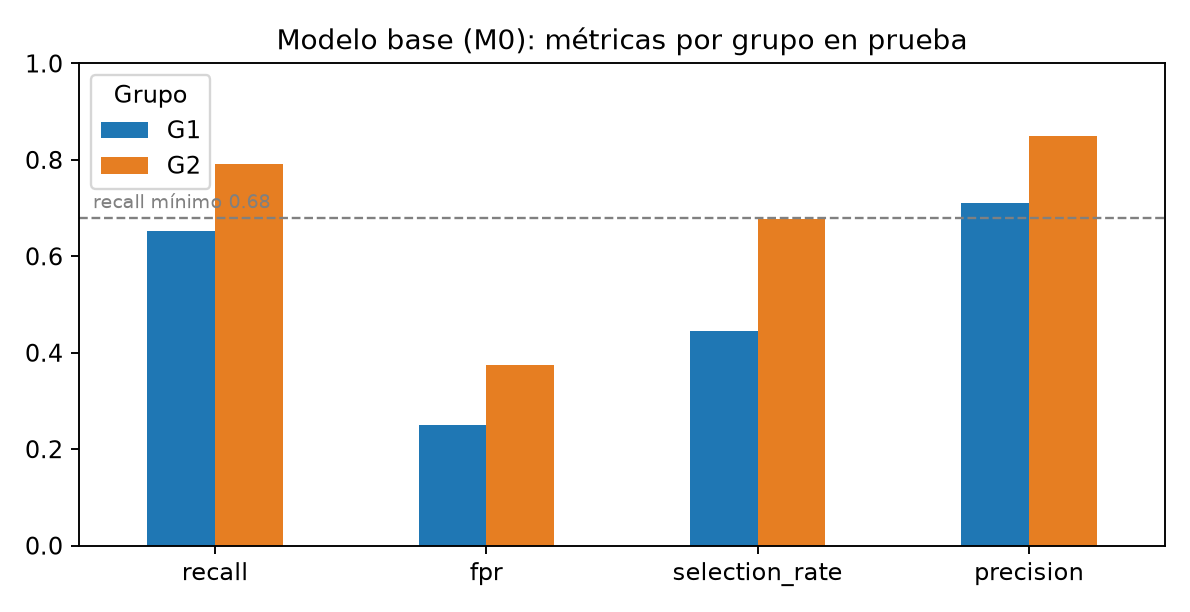

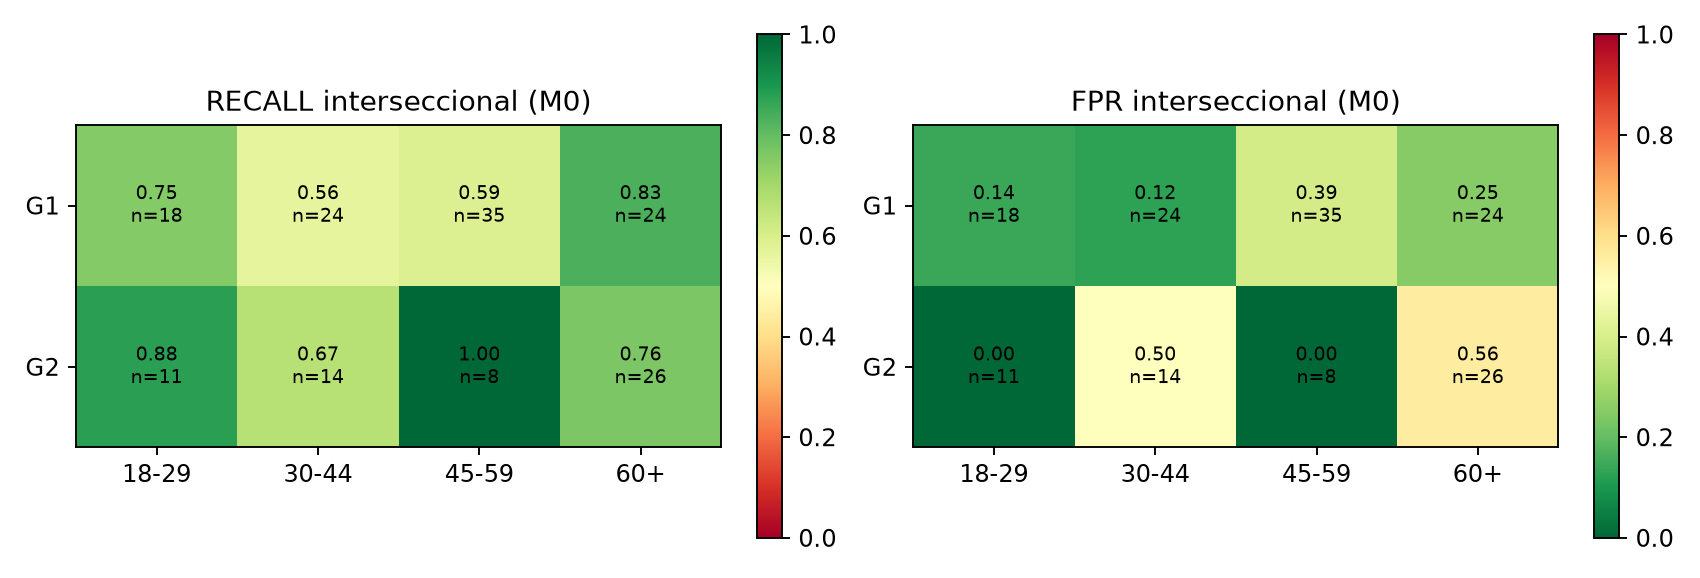

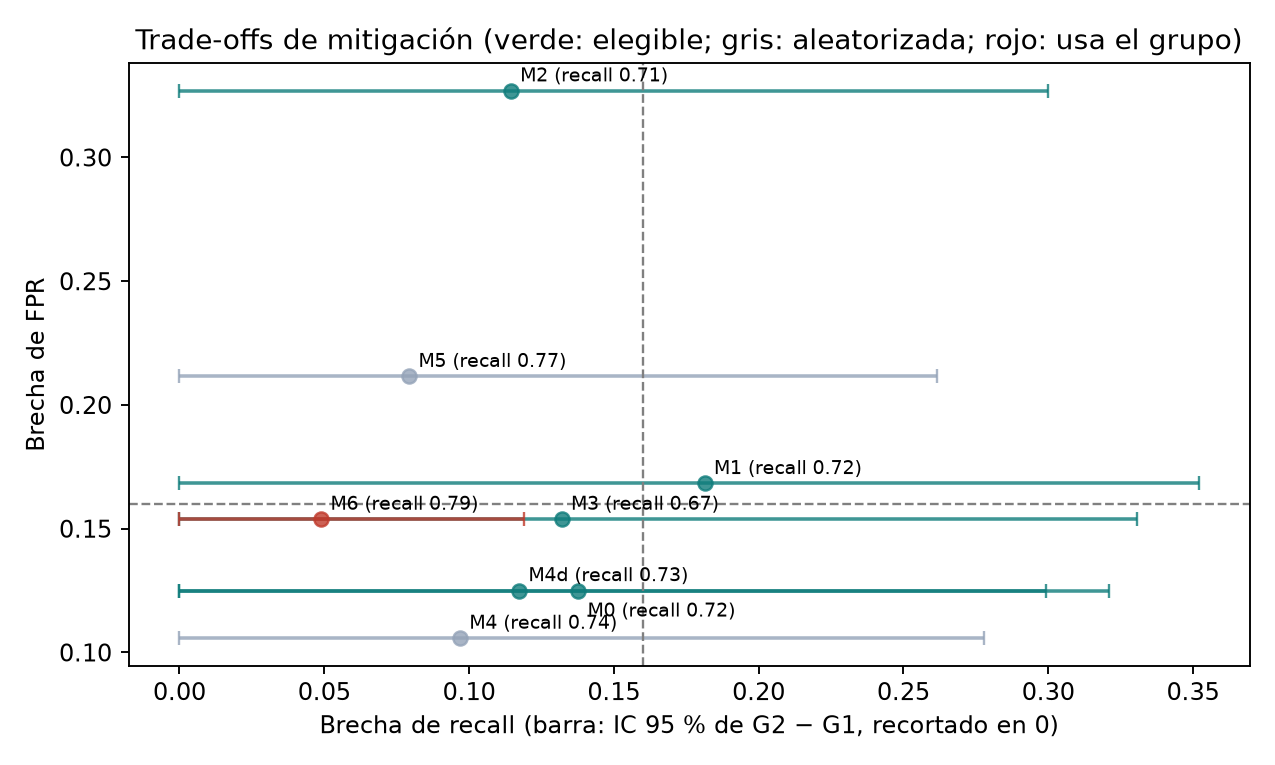

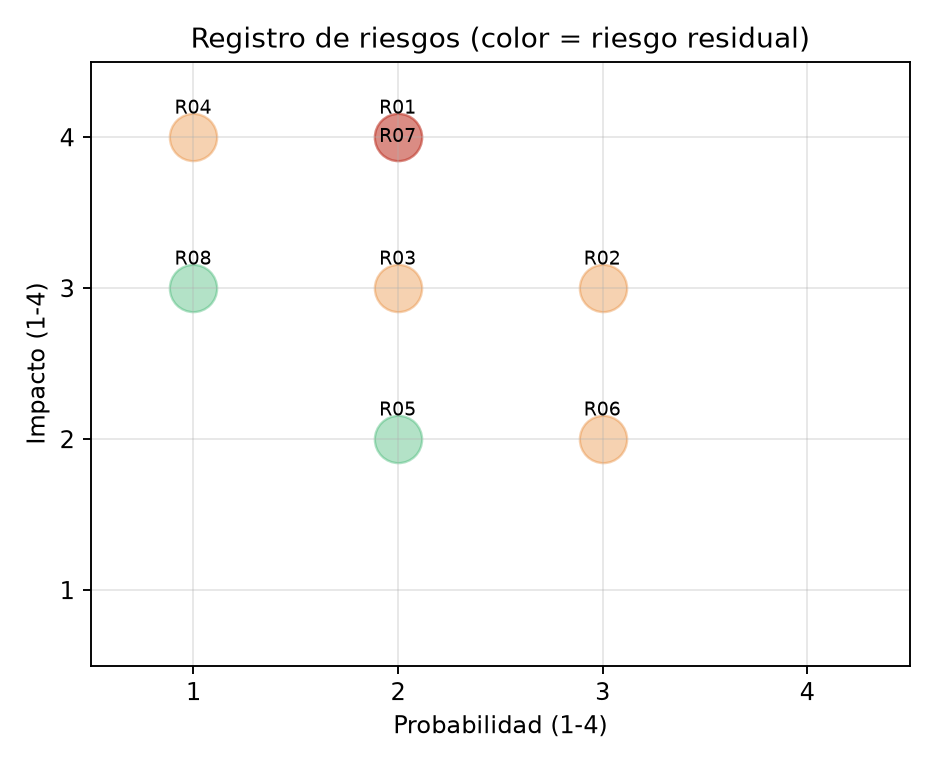

In [14]:
for f in ["fig_groups.png","fig_intersectional.png","fig_tradeoffs.png","fig_risk_matrix.png"]:
    display(Image(f"reports/figures/{f}", width=800))

## 7. Conclusión
Las puertas globales de LAB13 dicen **GO**, pero la auditoría muestra que G1 queda bajo el recall mínimo y que los intervalos no permiten certificar equidad. Ninguna mitigación elegible (determinista y sin usar el grupo al decidir) cumple los criterios estrictos. **Propuesta: MODIFICAR + LIMITAR** (M4d en piloto con revisión humana de todos los casos), a ratificar por la persona responsable.